In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_style("whitegrid")

In [16]:
X, y = make_blobs(n_samples=300, centers=4, 
                  cluster_std=1.2, random_state=42)

df = pd.DataFrame(X, columns=['Feature 1', 'Feature 2'])

print(df.head())

   Feature 1  Feature 2
0  -9.389561   6.303710
1  -9.870824   6.862056
2  -1.522144   7.549274
3  -7.140845  -5.561577
4 -11.284077   6.113819


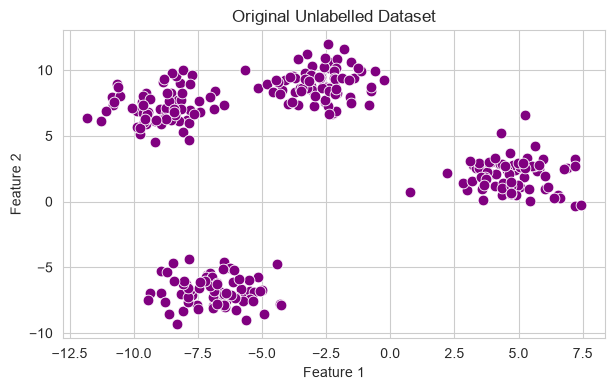

In [17]:
plt.figure(figsize=(7, 4))

sns.scatterplot(x=df['Feature 1'], y=df['Feature 2'],
                color='purple', s=60)

plt.title("Original Unlabelled Dataset")
plt.show()

In [18]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

kmeans_labels = kmeans.fit_predict(X)

df['Cluster'] = kmeans_labels

print(df.head())

   Feature 1  Feature 2  Cluster
0  -9.389561   6.303710        3
1  -9.870824   6.862056        3
2  -1.522144   7.549274        0
3  -7.140845  -5.561577        1
4 -11.284077   6.113819        3


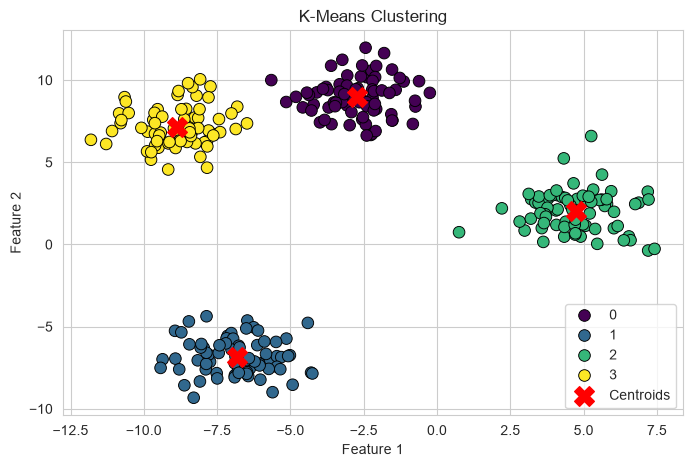

In [19]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='Feature 1', y='Feature 2',
                hue='Cluster', palette='viridis',
                s=70, edgecolor='black')

plt.scatter(kmeans.cluster_centers_[:, 0],
            kmeans.cluster_centers_[:, 1],
            color='red', marker='X', s=200,
            label='Centroids')

plt.title("K-Means Clustering")
plt.legend()
plt.show()

In [20]:
score = silhouette_score(X, kmeans_labels)

print("Silhouette Score:", score)

Silhouette Score: 0.7518318432861294


In [21]:
df = pd.read_csv("social_network_ads_practice.csv")

X = df[['Age', 'EstimatedSalary']]
y = df['Purchased']

print(df.head())

   Age  EstimatedSalary  Purchased
0   21           150732          1
1   51           120727          1
2   46            58577          1
3   36           147169          1
4   36            82906          1


In [22]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=10, random_state=42
)
bag.fit(X_train, y_train)

print("Decision Tree Accuracy:", accuracy_score(y_test, dt.predict(X_test)))
print("Bagging Accuracy:", accuracy_score(y_test, bag.predict(X_test)))

Decision Tree Accuracy: 0.6375
Bagging Accuracy: 0.65


In [23]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

print("Random Forest Accuracy:", accuracy_score(y_test, rf.predict(X_test)))

Random Forest Accuracy: 0.6625
